# 02 — Which of the 14 features actually say anything?

Notebook 01 proved the 14 modelling features are linearly independent of one another. That
is a statement about *redundancy*, not about *usefulness*: a column can be perfectly
independent and still tell you nothing about who wins.

This notebook asks the second question, and finds two features that are pure noise.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif

from lol import load, features, viz

viz.set_style()
pd.set_option("display.width", 200)

F = pd.read_parquet(load.processed_dir() / "games.parquet")
fcols = features.feature_columns(F)
X, y = F[fcols], F["blue_wins"]
print(f"{len(F):,} games · {len(fcols)} features · blue win rate {y.mean():.4f}")

33,755 games · 14 features · blue win rate 0.4995


## Signal, two ways

Correlation catches linear association; mutual information catches any dependence, including
the non-linear kind a decision tree can exploit. They are reported together so neither is
trusted alone.

In [2]:
signal = pd.DataFrame({
    "feature": fcols,
    "corr_with_result": [X[c].corr(y) for c in fcols],
    "mutual_information": mutual_info_classif(X, y, random_state=42),
})
signal["abs_corr"] = signal.corr_with_result.abs()
signal = signal.sort_values("abs_corr", ascending=False).reset_index(drop=True)
signal.round(4)

,feature,corr_with_result,mutual_information,abs_corr
0,total_gold_diff,0.5279,0.1694,0.5279
1,kills_diff,0.4972,0.1438,0.4972
2,avg_level_diff,0.4705,0.1320,0.4705
3,assists_diff,0.4153,0.0960,0.4153
4,total_minions_diff,0.3296,0.0623,0.3296
5,dragons_diff,0.2408,0.0329,0.2408
6,total_jungle_minions_diff,0.1828,0.0179,0.1828
7,towers_destroyed_diff,0.1451,0.0150,0.1451
8,heralds_diff,0.1328,0.0133,0.1328
9,first_blood_diff,0.1091,0.0064,0.1091


**The two match totals sit at zero.** `total_gold_both` and `total_kills_both` measure how
big the game was, not who is ahead in it — and the result does not care. A bloodbath and a
quiet farming game are equally likely to be won by either side.

That is the cleanest statement of this project's finding: at ten minutes, **only the gap
predicts the winner.** The absolute pace of the game carries nothing.

In [3]:
nice = lambda s: s.replace("_diff", " (difference)").replace("_both", " (match total)").replace("_", " ")
t = signal.sort_values("abs_corr")
dead = t.abs_corr < 0.02
fig, ax = plt.subplots(figsize=(7.6, 4.6))
ax.barh([nice(f) for f in t.feature], t.abs_corr,
        color=[viz.SERIES_2 if d else viz.SERIES_1 for d in dead], height=0.65)
for yy, (v, d) in enumerate(zip(t.abs_corr, dead)):
    ax.text(v + 0.008, yy, f"{v:.3f}", va="center", fontsize=9.5,
            color=viz.SERIES_2 if d else viz.TEXT_SECONDARY)
ax.set_xlim(0, 0.60)
ax.set_title("Only the gap predicts the winner — the match totals say nothing")
ax.set_xlabel("Absolute correlation with the result")
ax.grid(axis="y", visible=False)
plt.show()

<Figure size 836x506 with 1 Axes>

## Independent is not the same as uncorrelated

This distinction matters for B. The rank test in notebook 01 proved no feature is an exact
function of the others — that is why none can be dropped without losing information. It did
**not** prove they are unrelated. Kills give gold, so the two move together closely.

In [4]:
cm = X[signal.feature].corr()
pairs = cm.abs().where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().sort_values(ascending=False)
pd.DataFrame({"pair": [f"{a} ↔ {b}" for a, b in pairs.head(6).index],
              "abs correlation": pairs.head(6).round(3).values})

,pair,abs correlation
0,total_gold_diff ↔ kills_diff,0.919
1,total_gold_both ↔ total_kills_both,0.863
2,total_gold_diff ↔ avg_level_diff,0.851
3,kills_diff ↔ assists_diff,0.844
4,kills_diff ↔ avg_level_diff,0.777
5,total_gold_diff ↔ assists_diff,0.775


Six pairs exceed 0.7 and one reaches 0.92. Consequences, which belong in B's write-up:

* Trees and KNN are untroubled by this — they do not assume independent predictors.
* **Interpretation is troubled by it.** With `kills_diff` and `total_gold_diff` at 0.92,
  whichever the tree happens to split on first will look far more important than the other.
  Any claim of the form "gold matters more than kills" has to survive that caveat.

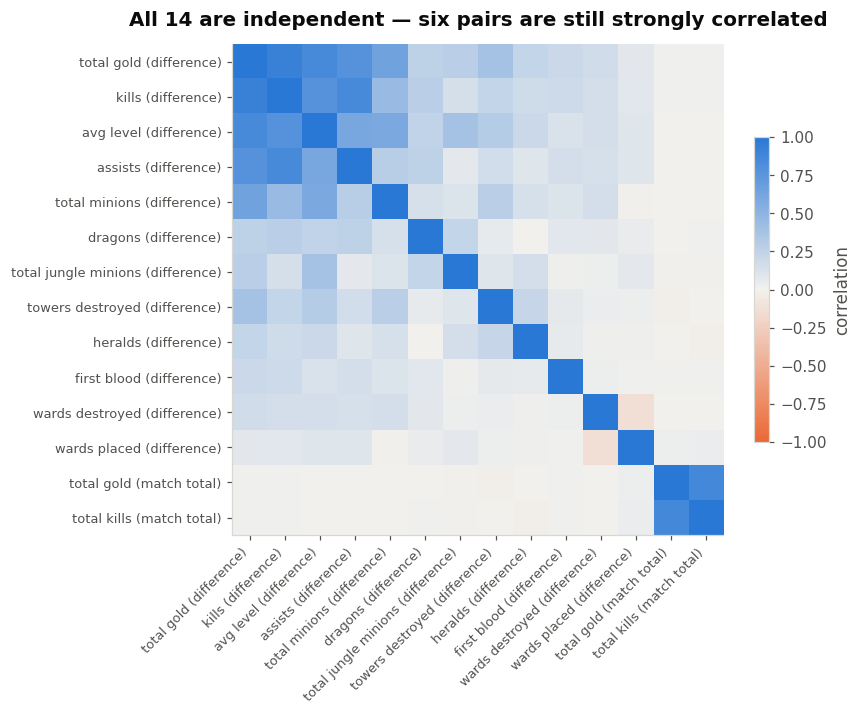

In [5]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", [viz.SERIES_2, "#f2f1ee", viz.SERIES_1])
fig, ax = plt.subplots(figsize=(7.2, 6.0))
im = ax.imshow(cm, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_yticks(range(len(cm)))
ax.set_xticklabels([nice(f) for f in cm.columns], rotation=45, ha="right", fontsize=8.5)
ax.set_yticklabels([nice(f) for f in cm.index], fontsize=8.5)
ax.set_title("All 14 are independent — six pairs are still strongly correlated", pad=12)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="correlation")
plt.show()

The block structure is the story: a tight cluster of "who is ahead" measures in the top
left, and the two match totals isolated in the bottom right, correlated with each other and
with nothing that matters.

## Does the ranking hold in both tiers?

Q4 asks whether a model fit on Diamond transfers to Challenger. If the features carried
completely different weight at the two skill levels, that transfer would be hopeless before
we started.

In [6]:
by_tier = pd.DataFrame({
    "feature": signal.feature,
    "Diamond": [F.loc[F.tier == "diamond", c].corr(F.loc[F.tier == "diamond", "blue_wins"]) for c in signal.feature],
    "Challenger": [F.loc[F.tier == "challenger", c].corr(F.loc[F.tier == "challenger", "blue_wins"]) for c in signal.feature],
}).round(3)
by_tier["gap"] = (by_tier.Diamond - by_tier.Challenger).abs().round(3)
by_tier

/Users/cesarley/Desktop/Augusto/7MOSEM/Data Mining/Project/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/cesarley/Desktop/Augusto/7MOSEM/Data Mining/Project/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,feature,Diamond,Challenger,gap
0,total_gold_diff,0.511,0.535,0.024
1,kills_diff,0.479,0.505,0.026
2,avg_level_diff,0.453,0.478,0.025
3,assists_diff,0.386,0.427,0.041
4,total_minions_diff,0.309,0.338,0.029
5,dragons_diff,0.234,0.244,0.010
6,total_jungle_minions_diff,0.169,0.188,0.019
7,towers_destroyed_diff,0.156,0.141,0.015
8,heralds_diff,0.122,0.137,0.015
9,first_blood_diff,0.202,NaN,NaN


## What this notebook established

1. **Gold difference is the strongest single signal**, followed by kills, level and assists —
   all measures of the same underlying lead, which is why they correlate so tightly.
2. **The two match totals carry no signal at all.** Only the gap predicts the winner. They
   are kept in the table so the finding can be shown rather than asserted, and B should
   expect any reasonable feature-selection method to discard them.
3. **Independence is not the absence of correlation.** Six pairs exceed 0.7, which constrains
   how confidently feature importances can be read.
4. **The feature ranking is broadly similar in both tiers**, which is the precondition for
   Q4 being a fair test rather than a foregone failure.